In [73]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder,LabelEncoder

In [74]:
df = pd.read_csv('diabetes_patients_10000_full.csv')

In [75]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Patient_ID         10000 non-null  int64  
 1   Age                9986 non-null   float64
 2   Gender             9960 non-null   object 
 3   Blood_Sugar_Level  9947 non-null   float64
 4   Creatinine         9944 non-null   float64
 5   BMI                9949 non-null   float64
 6   Urea               9949 non-null   float64
 7   Cholesterol        9968 non-null   float64
 8   HbA1c              10000 non-null  float64
 9   Class              10000 non-null  object 
dtypes: float64(7), int64(1), object(2)
memory usage: 781.4+ KB


In [76]:
df.drop(columns = ['Patient_ID'],inplace = True)

In [77]:
df.duplicated().sum()

0

In [78]:
df.isnull().sum()

Age                  14
Gender               40
Blood_Sugar_Level    53
Creatinine           56
BMI                  51
Urea                 51
Cholesterol          32
HbA1c                 0
Class                 0
dtype: int64

In [79]:
df = df.dropna()

In [80]:
df.columns

Index(['Age', 'Gender', 'Blood_Sugar_Level', 'Creatinine', 'BMI', 'Urea',
       'Cholesterol', 'HbA1c', 'Class'],
      dtype='object')

In [81]:
df.head()

,Age,Gender,Blood_Sugar_Level,Creatinine,BMI,Urea,Cholesterol,HbA1c,Class
0,60.0,Male,96.0,1.34,22.5,23.0,176.0,8.6,Diabetic
1,77.0,Male,241.0,1.02,19.0,28.0,209.0,7.5,Diabetic
2,21.0,Male,229.0,1.02,25.9,32.0,151.0,9.1,Diabetic
3,30.0,Female,177.0,0.88,22.1,36.0,176.0,5.1,Diabetic
4,26.0,Female,178.0,1.20,31.8,44.0,287.0,5.2,Diabetic


In [82]:
df['Class'] = df['Class'].map({'Non-Diabetic': 0, 'Diabetic': 1})
df['Gender'] = df['Gender'].map({'Male': 0, 'Female': 1})

In [83]:
y = df['Class']
X = df.drop(columns = ['Class'])

In [84]:
X_train, X_test,y_train,y_test = train_test_split(X,y,test_size=.2,random_state= 10)

C:\Users\yawaa\AppData\Local\Temp\ipykernel_31096\763283344.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Class', palette='Set2')


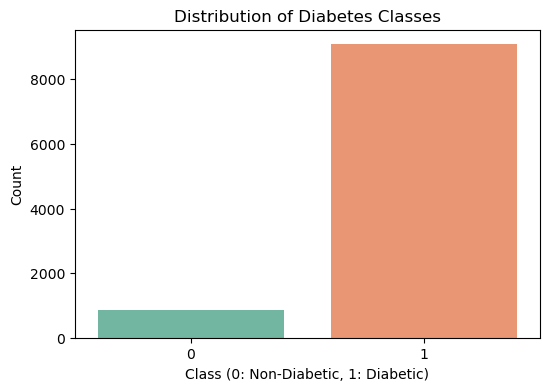

In [85]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Class', palette='Set2')
plt.title('Distribution of Diabetes Classes')
plt.xlabel('Class (0: Non-Diabetic, 1: Diabetic)')
plt.ylabel('Count')
plt.show()

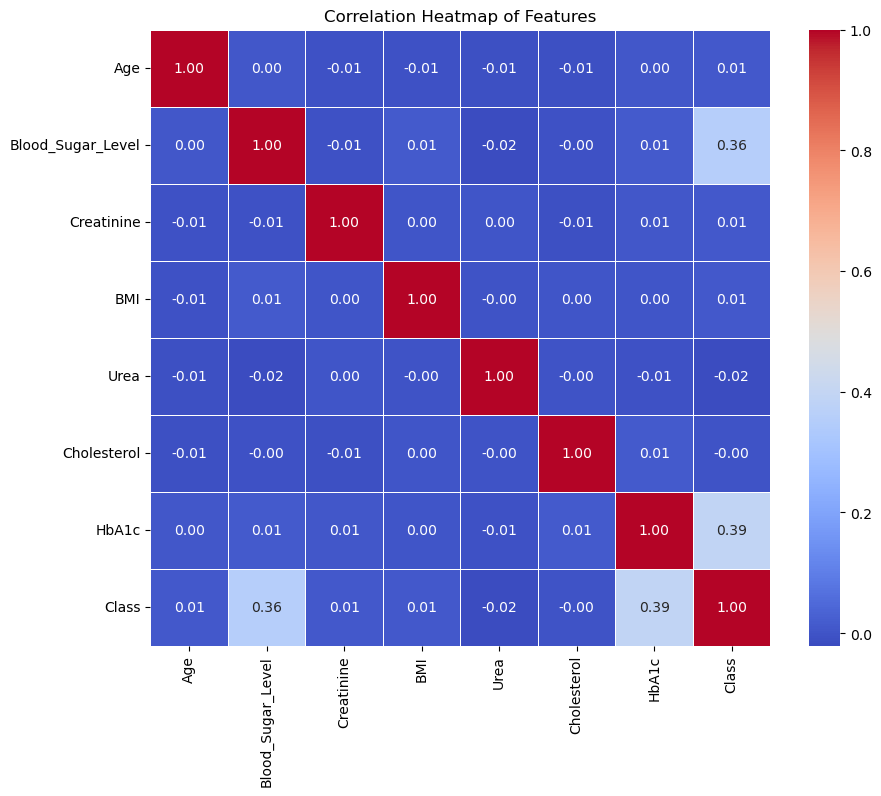

In [86]:
plt.figure(figsize=(10, 8))
numeric_cols = ['Age', 'Blood_Sugar_Level', 'Creatinine', 'BMI', 'Urea', 'Cholesterol', 'HbA1c', 'Class']
corr = df[numeric_cols].corr()

sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap of Features')
plt.show()

C:\Users\yawaa\AppData\Local\Temp\ipykernel_31096\509056530.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Class', y='Blood_Sugar_Level', ax=axes[0], palette='Set2')
C:\Users\yawaa\AppData\Local\Temp\ipykernel_31096\509056530.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Class', y='HbA1c', ax=axes[1], palette='Set2')


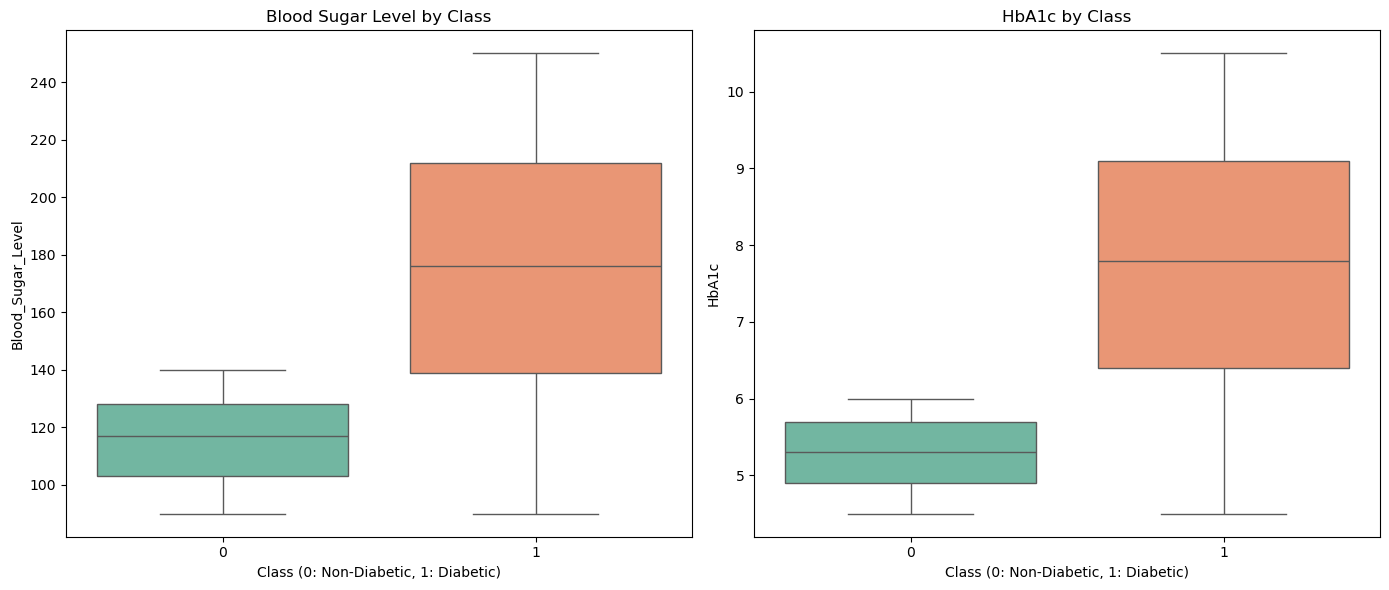

In [87]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.boxplot(data=df, x='Class', y='Blood_Sugar_Level', ax=axes[0], palette='Set2')
axes[0].set_title('Blood Sugar Level by Class')
axes[0].set_xlabel('Class (0: Non-Diabetic, 1: Diabetic)')

sns.boxplot(data=df, x='Class', y='HbA1c', ax=axes[1], palette='Set2')
axes[1].set_title('HbA1c by Class')
axes[1].set_xlabel('Class (0: Non-Diabetic, 1: Diabetic)')

plt.tight_layout()
plt.show()

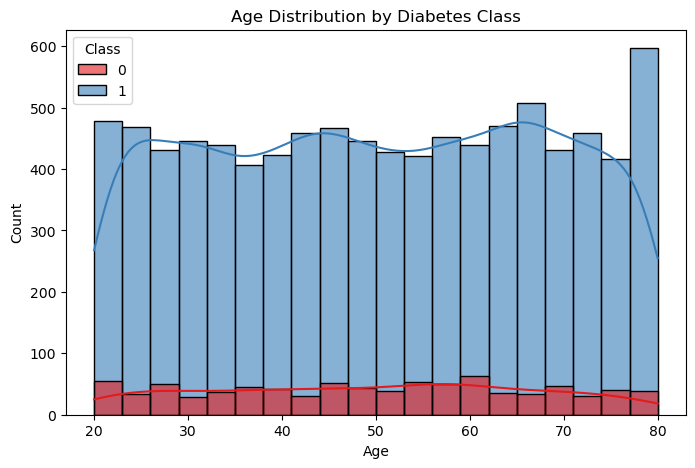

In [88]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='Age', hue='Class', kde=True, palette='Set1', bins=20, alpha=0.6)
plt.title('Age Distribution by Diabetes Class')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()

In [89]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, accuracy_score

# 1. Scale the training and testing features directly
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 2. Define the model (without pipeline)
lr = LogisticRegression(random_state=42)

# 3. Define hyperparameter grid (notice the prefix change: 'clf__' is removed)
param_grid_lr = {
    'C': [0.01, 0.1, 1, 10, 100],
    'solver': ['liblinear', 'lbfgs']
}

# 4. Grid Search
grid_lr = GridSearchCV(lr, param_grid_lr, cv=5, scoring='accuracy')
grid_lr.fit(X_train_scaled, y_train)

# 5. Results & Evaluation
print("=== Logistic Regression Results ===")
print("Best Parameters:", grid_lr.best_params_)
print("Best CV Score:", grid_lr.best_score_)

y_pred_lr = grid_lr.predict(X_test_scaled)
print("\nTest Accuracy:", accuracy_score(y_test, y_pred_lr))
print("\nClassification Report:\n", classification_report(y_test, y_pred_lr))

=== Logistic Regression Results ===
Best Parameters: {'C': 10, 'solver': 'lbfgs'}
Best CV Score: 0.9734424166142228

Test Accuracy: 0.96527428283845

Classification Report:
               precision    recall  f1-score   support

           0       0.77      0.82      0.80       164
           1       0.98      0.98      0.98      1823

    accuracy                           0.97      1987
   macro avg       0.88      0.90      0.89      1987
weighted avg       0.97      0.97      0.97      1987



e:\anaconda\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


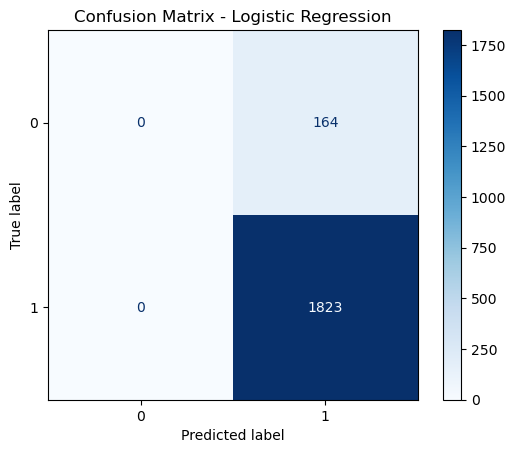

In [90]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
y_pred_lr = grid_lr.predict(X_test)
cm_lr = confusion_matrix(y_test, y_pred_lr)
disp_lr = ConfusionMatrixDisplay(confusion_matrix=cm_lr, display_labels=grid_lr.classes_)

disp_lr.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

In [91]:
from sklearn.naive_bayes import GaussianNB

# Naive Bayes doesn't require feature scaling
nb = GaussianNB()

# Define hyperparameter grid
param_grid_nb = {
    'var_smoothing': [1e-9, 1e-8, 1e-7, 1e-6, 1e-5]
}

# Grid Search
grid_nb = GridSearchCV(nb, param_grid_nb, cv=5, scoring='accuracy')
grid_nb.fit(X_train, y_train)

# Results & Evaluation
print("=== Naive Bayes Results ===")
print("Best Parameters:", grid_nb.best_params_)
print("Best CV Score:", grid_nb.best_score_)

y_pred_nb = grid_nb.predict(X_test)
print("\nTest Accuracy:", accuracy_score(y_test, y_pred_nb))
print("\nClassification Report:\n", classification_report(y_test, y_pred_nb))

=== Naive Bayes Results ===
Best Parameters: {'var_smoothing': 1e-05}
Best CV Score: 0.9903083700440529

Test Accuracy: 0.9909411172622044

Classification Report:
               precision    recall  f1-score   support

           0       0.99      0.90      0.94       164
           1       0.99      1.00      1.00      1823

    accuracy                           0.99      1987
   macro avg       0.99      0.95      0.97      1987
weighted avg       0.99      0.99      0.99      1987



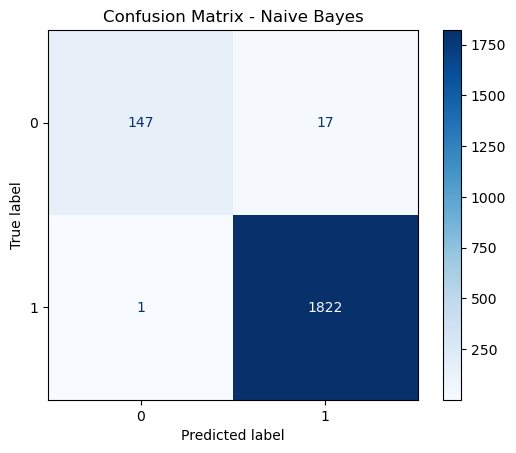

In [92]:
y_pred_nb = grid_nb.predict(X_test)
cm_nb = confusion_matrix(y_test, y_pred_nb)
disp_nb = ConfusionMatrixDisplay(confusion_matrix=cm_nb, display_labels=grid_nb.classes_)

disp_nb.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix - Naive Bayes")
plt.show()

In [93]:
from sklearn.pipeline import Pipeline

In [94]:
from sklearn.svm import SVC

# Define pipeline with scaler (SVM performs much better with scaled data)
pipeline_svm = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', SVC(random_state=42))
])

# Define hyperparameter grid
param_grid_svm = {
    'clf__C': [0.1, 1, 10, 100],
    'clf__kernel': ['linear', 'rbf'],
    'clf__gamma': ['scale', 'auto']
}

# Grid Search
grid_svm = GridSearchCV(pipeline_svm, param_grid_svm, cv=5, scoring='accuracy')
grid_svm.fit(X_train, y_train)

# Results & Evaluation
print("=== Support Vector Machine Results ===")
print("Best Parameters:", grid_svm.best_params_)
print("Best CV Score:", grid_svm.best_score_)

y_pred_svm = grid_svm.predict(X_test)
print("\nTest Accuracy:", accuracy_score(y_test, y_pred_svm))
print("\nClassification Report:\n", classification_report(y_test, y_pred_svm))



=== Support Vector Machine Results ===
Best Parameters: {'clf__C': 100, 'clf__gamma': 'scale', 'clf__kernel': 'rbf'}
Best CV Score: 0.9859030837004404

Test Accuracy: 0.9833920483140413

Classification Report:
               precision    recall  f1-score   support

           0       0.88      0.92      0.90       164
           1       0.99      0.99      0.99      1823

    accuracy                           0.98      1987
   macro avg       0.94      0.95      0.95      1987
weighted avg       0.98      0.98      0.98      1987



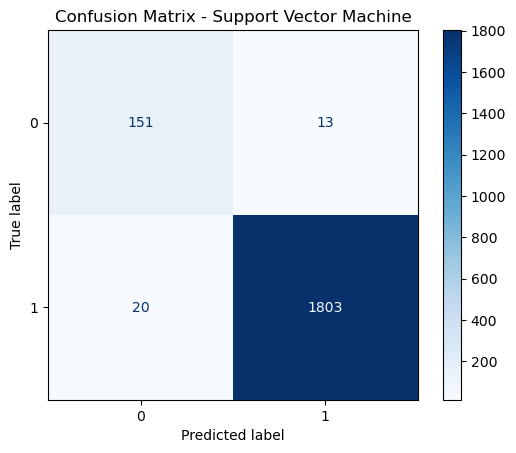

In [95]:
y_pred_svm = grid_svm.predict(X_test)
cm_svm = confusion_matrix(y_test, y_pred_svm)
disp_svm = ConfusionMatrixDisplay(confusion_matrix=cm_svm, display_labels=grid_svm.classes_)

disp_svm.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix - Support Vector Machine")
plt.show()

In [96]:
from sklearn.tree import DecisionTreeClassifier

# Decision Trees are scale-invariant, so scaling isn't necessary
dt = DecisionTreeClassifier(random_state=42)

# Define hyperparameter grid
param_grid_dt = {
    'max_depth': [None, 3, 5, 10, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'criterion': ['gini', 'entropy']
}

# Grid Search
grid_dt = GridSearchCV(dt, param_grid_dt, cv=5, scoring='accuracy')
grid_dt.fit(X_train, y_train)

# Results & Evaluation
print("=== Decision Tree Results ===")
print("Best Parameters:", grid_dt.best_params_)
print("Best CV Score:", grid_dt.best_score_)

y_pred_dt = grid_dt.predict(X_test)
print("\nTest Accuracy:", accuracy_score(y_test, y_pred_dt))
print("\nClassification Report:\n", classification_report(y_test, y_pred_dt))

=== Decision Tree Results ===
Best Parameters: {'criterion': 'gini', 'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2}
Best CV Score: 1.0

Test Accuracy: 1.0

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00       164
           1       1.00      1.00      1.00      1823

    accuracy                           1.00      1987
   macro avg       1.00      1.00      1.00      1987
weighted avg       1.00      1.00      1.00      1987



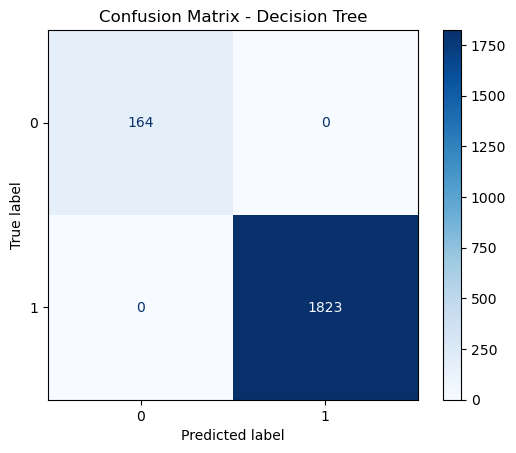

In [97]:
y_pred_dt = grid_dt.predict(X_test)
cm_dt = confusion_matrix(y_test, y_pred_dt)
disp_dt = ConfusionMatrixDisplay(confusion_matrix=cm_dt, display_labels=grid_dt.classes_)

disp_dt.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix - Decision Tree")
plt.show()

C:\Users\yawaa\AppData\Local\Temp\ipykernel_31096\2832317202.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=features_df, x='Importance', y='Feature', palette='viridis')


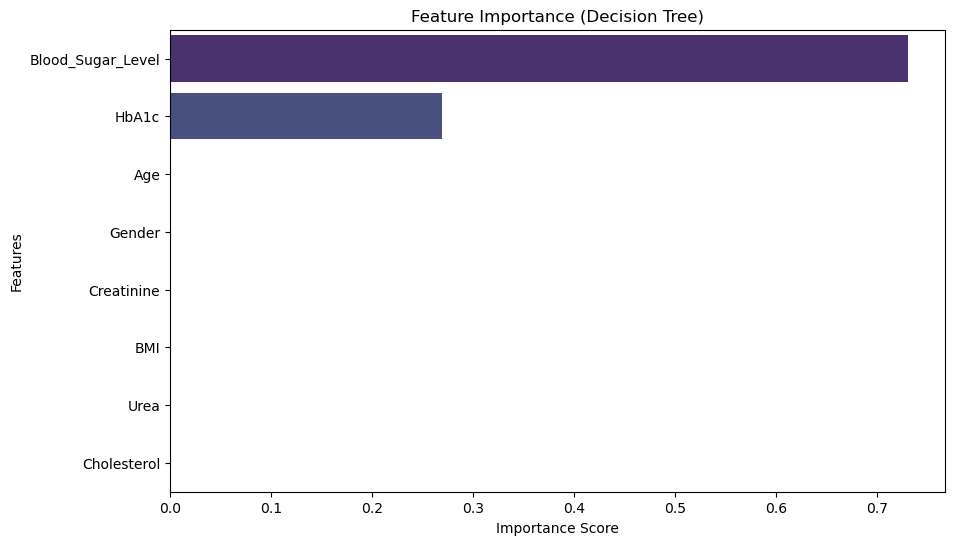

             Feature  Importance
2  Blood_Sugar_Level    0.730807
7              HbA1c    0.269193
0                Age    0.000000
1             Gender    0.000000
3         Creatinine    0.000000
4                BMI    0.000000
5               Urea    0.000000
6        Cholesterol    0.000000


In [98]:


feature_importances = grid_dt.best_estimator_.feature_importances_

# 2. Create a DataFrame for easy plotting
features_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': feature_importances
}).sort_values(by='Importance', ascending=False)

# 3. Plot the feature importances
plt.figure(figsize=(10, 6))
sns.barplot(data=features_df, x='Importance', y='Feature', palette='viridis')
plt.title('Feature Importance (Decision Tree)')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.show()

# Print the table of importances
print(features_df)

In [99]:
from tqdm import tqdm
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    balanced_accuracy_score,
    roc_auc_score,roc_curve,
    precision_recall_curve,average_precision_score
)
# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from sklearn.naive_bayes import GaussianNB

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    VotingClassifier,
    StackingClassifier
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier


In [100]:
models = {

    # Linear
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=1),

    # Distance-based
    "KNN": KNeighborsClassifier(n_neighbors=5),

    # SVM
    "SVC": SVC(probability=True, random_state=1),

    # Tree
    "Decision Tree": DecisionTreeClassifier(random_state=1),

    # Naive Bayes
    "Naive Bayes": GaussianNB(),

    # Bagging Based
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=100, random_state=1),

    # Boosting
    "AdaBoost": AdaBoostClassifier(random_state=1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=1),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=1),

    # External Boosting Libraries
    "XGBoost": XGBClassifier(eval_metric='logloss', random_state=1, use_label_encoder=False),
    "CatBoost": CatBoostClassifier(verbose=0, random_state=1),
    "LightGBM": LGBMClassifier(random_state=1)
}

  0%|          | 0/13 [00:00<?, ?it/s]


Confusion Matrix:
 [[ 134   30]
 [  40 1783]]


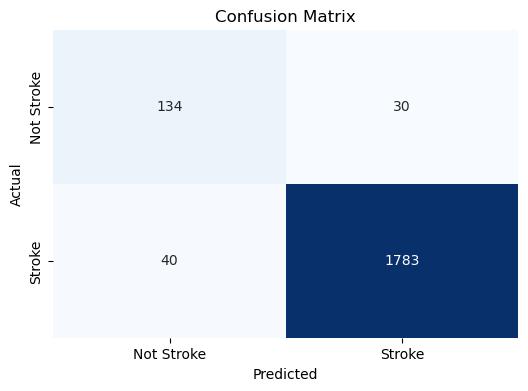


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.77      0.82      0.79       164
      Stroke       0.98      0.98      0.98      1823

    accuracy                           0.96      1987
   macro avg       0.88      0.90      0.89      1987
weighted avg       0.97      0.96      0.97      1987

ROC-AUC: 0.9888885915737928


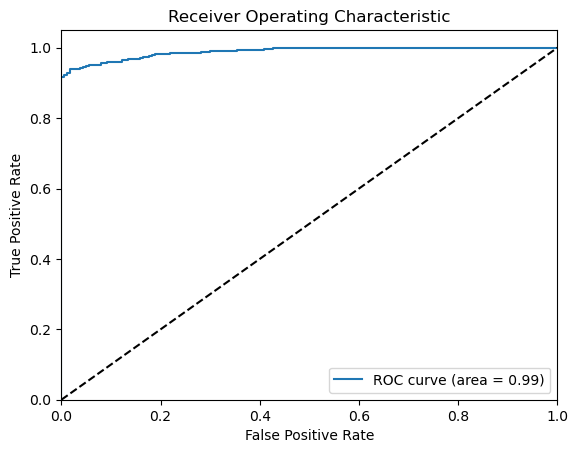

PR AUC: 0.9990017301788712


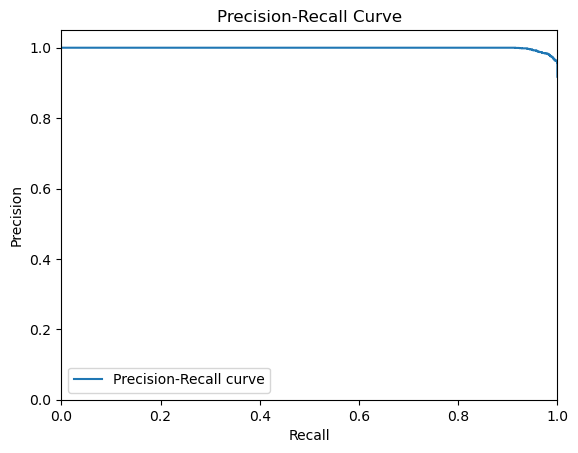

  8%|▊         | 1/13 [00:00<00:09,  1.29it/s]


Confusion Matrix:
 [[  27  137]
 [  41 1782]]


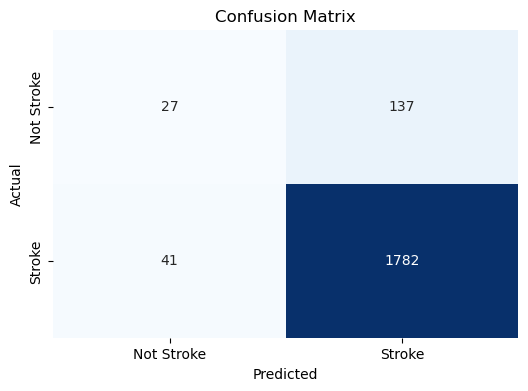


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.40      0.16      0.23       164
      Stroke       0.93      0.98      0.95      1823

    accuracy                           0.91      1987
   macro avg       0.66      0.57      0.59      1987
weighted avg       0.88      0.91      0.89      1987

ROC-AUC: 0.8246140106765851


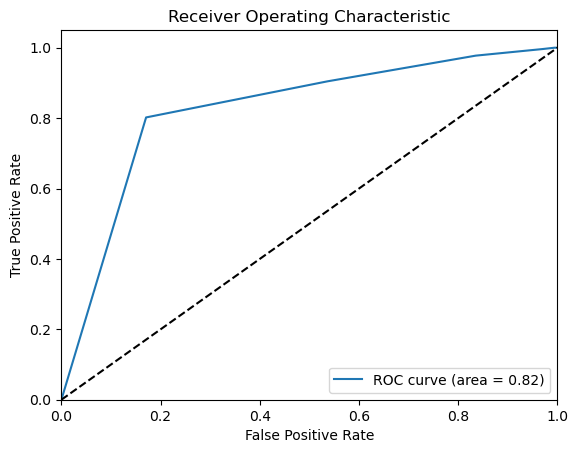

PR AUC: 0.9727073959070928


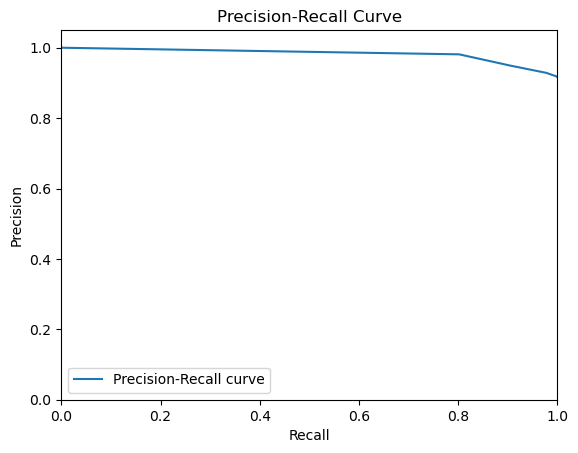

 15%|█▌        | 2/13 [00:02<00:11,  1.05s/it]e:\anaconda\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(



Confusion Matrix:
 [[   0  164]
 [   0 1823]]


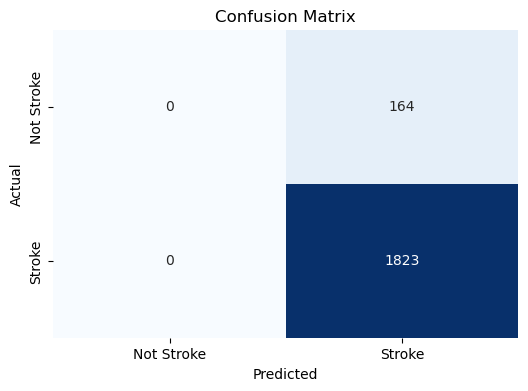


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.00      0.00      0.00       164
      Stroke       0.92      1.00      0.96      1823

    accuracy                           0.92      1987
   macro avg       0.46      0.50      0.48      1987
weighted avg       0.84      0.92      0.88      1987

ROC-AUC: 0.9910192258806845


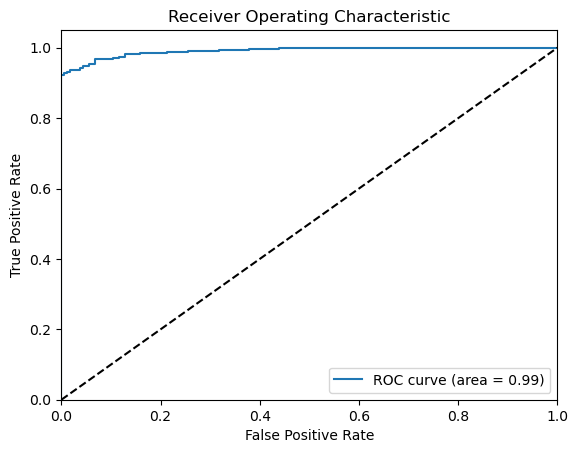

PR AUC: 0.9991932769809422


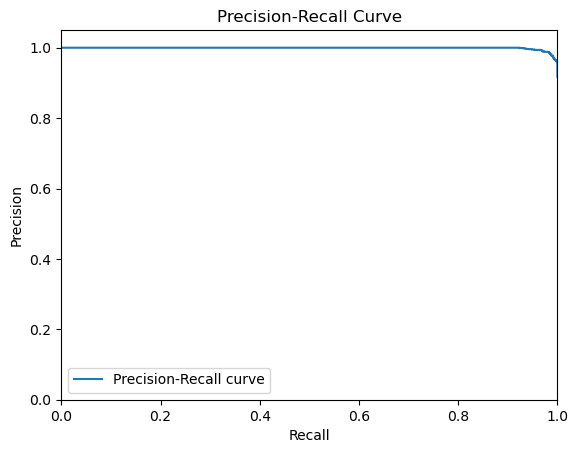

 23%|██▎       | 3/13 [00:08<00:37,  3.76s/it]


Confusion Matrix:
 [[ 164    0]
 [   0 1823]]


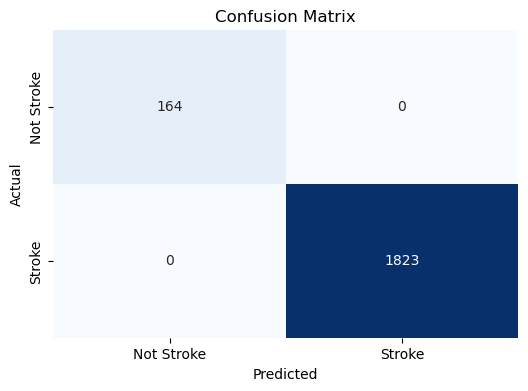


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       1.00      1.00      1.00       164
      Stroke       1.00      1.00      1.00      1823

    accuracy                           1.00      1987
   macro avg       1.00      1.00      1.00      1987
weighted avg       1.00      1.00      1.00      1987

ROC-AUC: 1.0


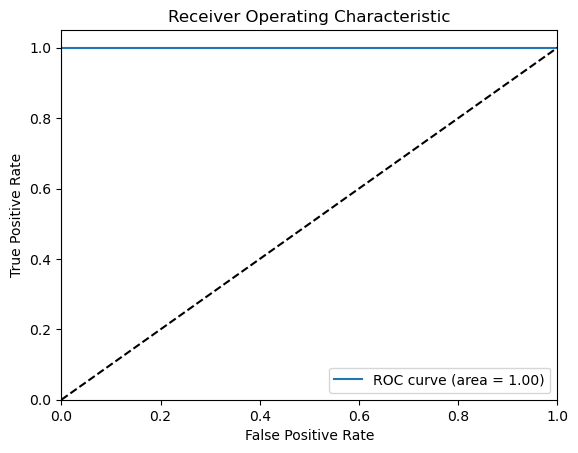

PR AUC: 1.0


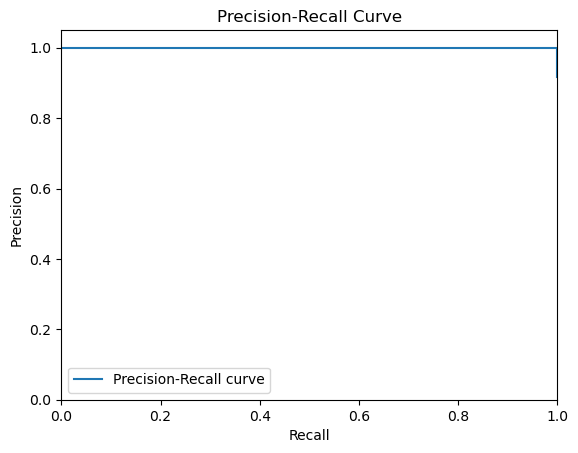

 31%|███       | 4/13 [00:09<00:22,  2.50s/it]


Confusion Matrix:
 [[ 145   19]
 [   1 1822]]


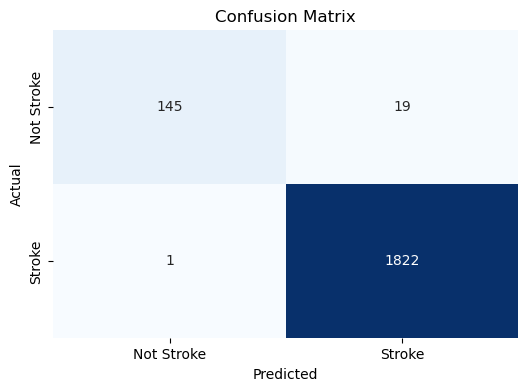


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.99      0.88      0.94       164
      Stroke       0.99      1.00      0.99      1823

    accuracy                           0.99      1987
   macro avg       0.99      0.94      0.97      1987
weighted avg       0.99      0.99      0.99      1987

ROC-AUC: 0.9992206628045436


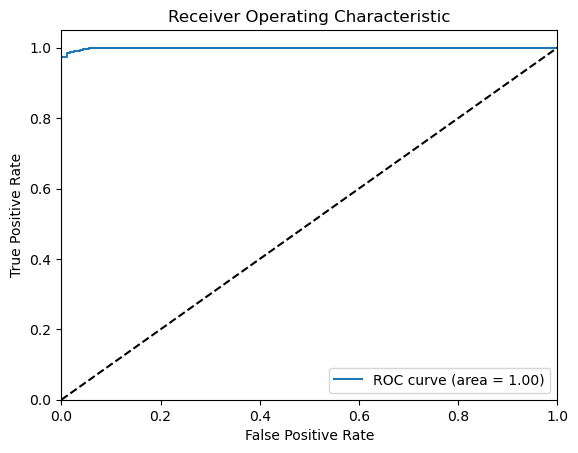

PR AUC: 0.9999296649237438


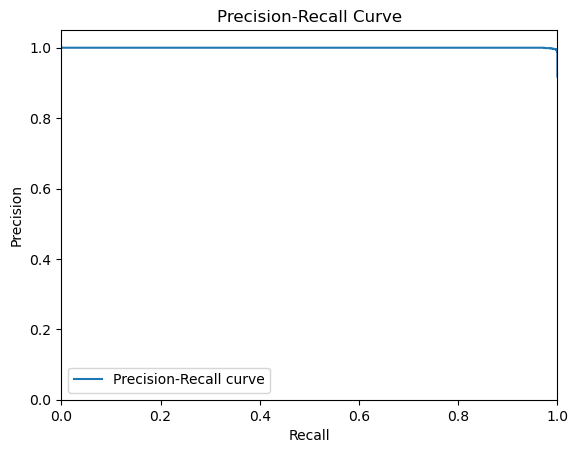

 38%|███▊      | 5/13 [00:10<00:14,  1.82s/it]


Confusion Matrix:
 [[ 164    0]
 [   0 1823]]


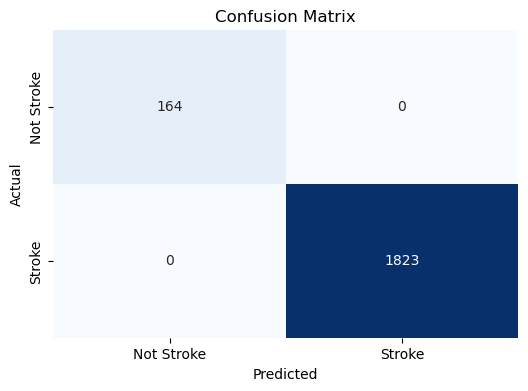


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       1.00      1.00      1.00       164
      Stroke       1.00      1.00      1.00      1823

    accuracy                           1.00      1987
   macro avg       1.00      1.00      1.00      1987
weighted avg       1.00      1.00      1.00      1987

ROC-AUC: 1.0


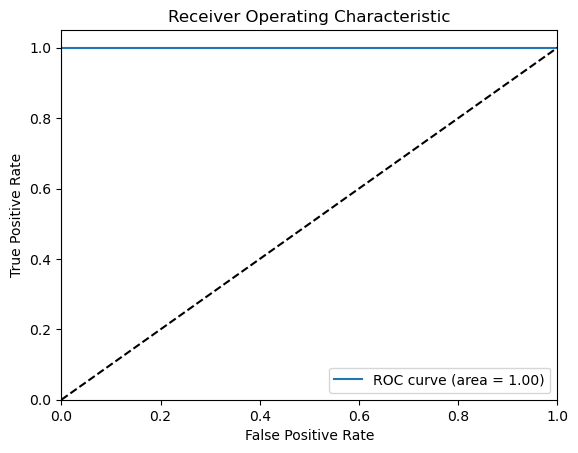

PR AUC: 1.0


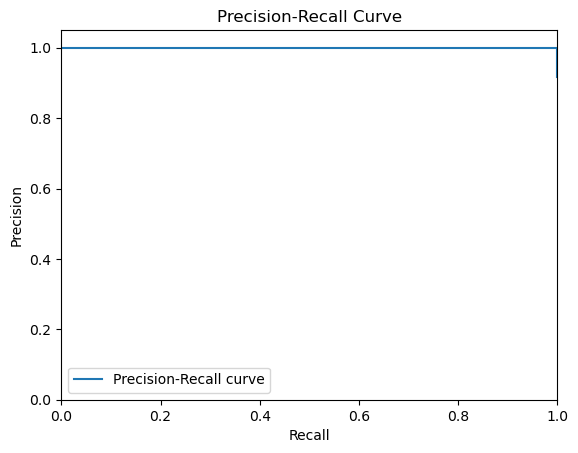

 46%|████▌     | 6/13 [00:11<00:11,  1.57s/it]


Confusion Matrix:
 [[ 143   21]
 [   2 1821]]


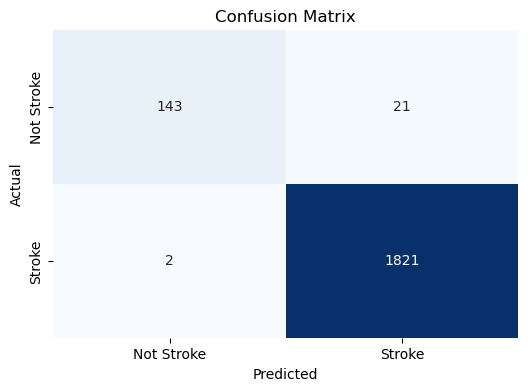


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.99      0.87      0.93       164
      Stroke       0.99      1.00      0.99      1823

    accuracy                           0.99      1987
   macro avg       0.99      0.94      0.96      1987
weighted avg       0.99      0.99      0.99      1987

ROC-AUC: 0.9992591279450919


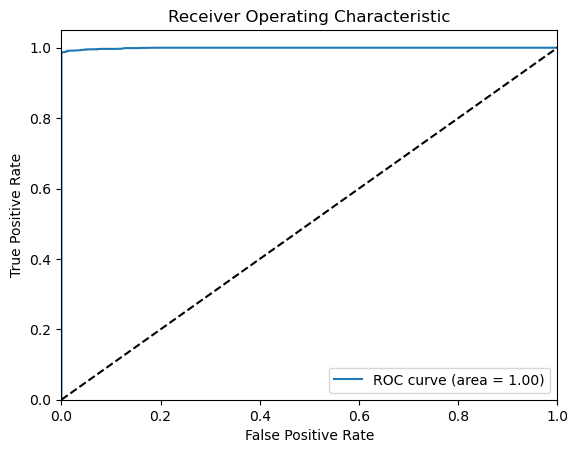

PR AUC: 0.9999303553912391


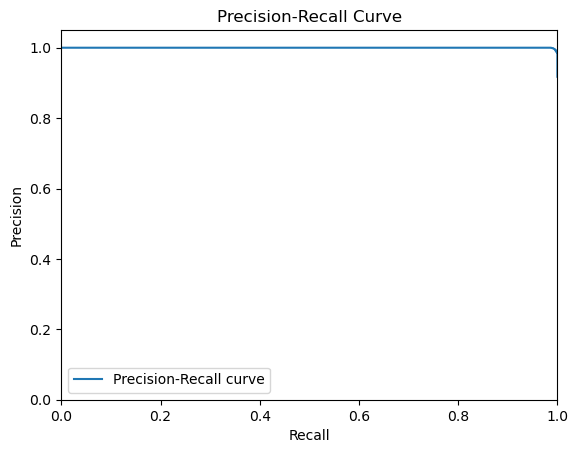

 54%|█████▍    | 7/13 [00:12<00:09,  1.50s/it]


Confusion Matrix:
 [[ 164    0]
 [   0 1823]]


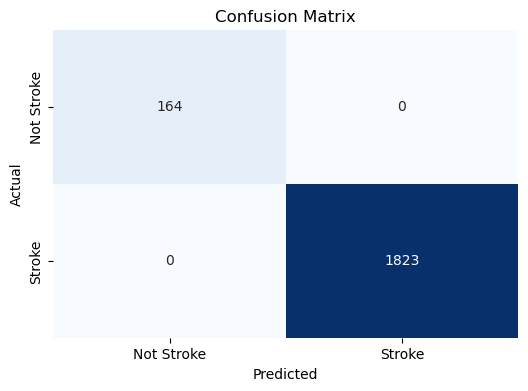


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       1.00      1.00      1.00       164
      Stroke       1.00      1.00      1.00      1823

    accuracy                           1.00      1987
   macro avg       1.00      1.00      1.00      1987
weighted avg       1.00      1.00      1.00      1987

ROC-AUC: 1.0


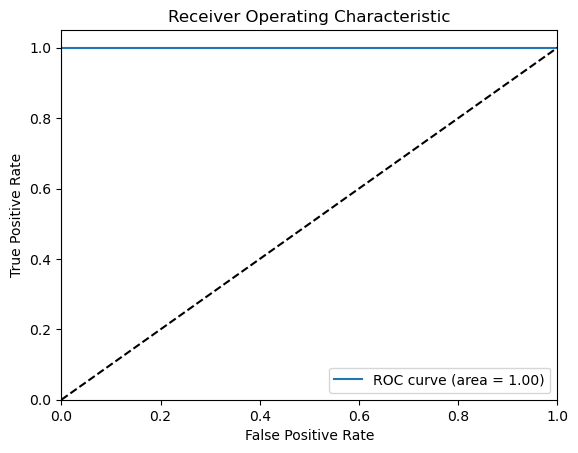

PR AUC: 1.0


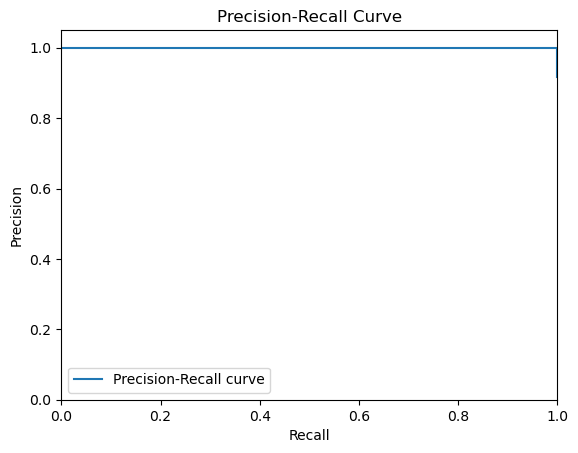

 62%|██████▏   | 8/13 [00:13<00:07,  1.40s/it]


Confusion Matrix:
 [[ 164    0]
 [   0 1823]]


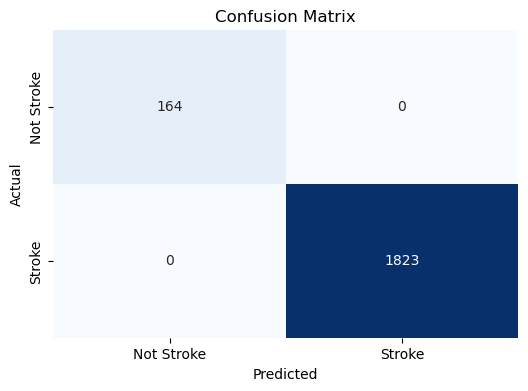


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       1.00      1.00      1.00       164
      Stroke       1.00      1.00      1.00      1823

    accuracy                           1.00      1987
   macro avg       1.00      1.00      1.00      1987
weighted avg       1.00      1.00      1.00      1987

ROC-AUC: 1.0


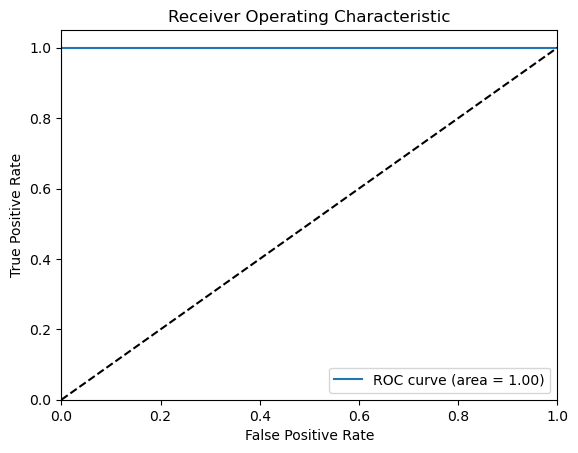

PR AUC: 1.0


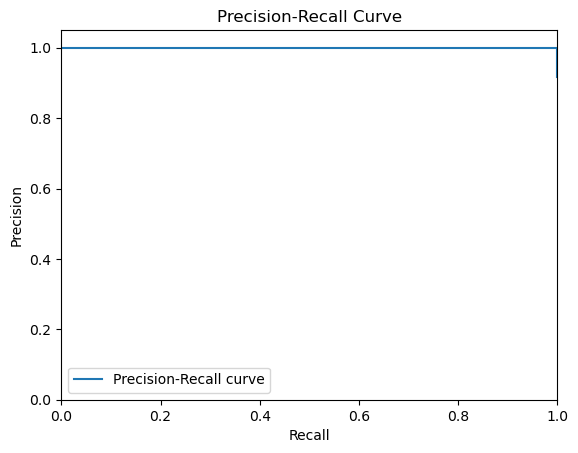

 69%|██████▉   | 9/13 [00:15<00:05,  1.41s/it]e:\anaconda\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "e:\anaconda\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "e:\anaconda\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "e:\anaconda\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "e:\anaconda\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, ar


Confusion Matrix:
 [[ 164    0]
 [   0 1823]]


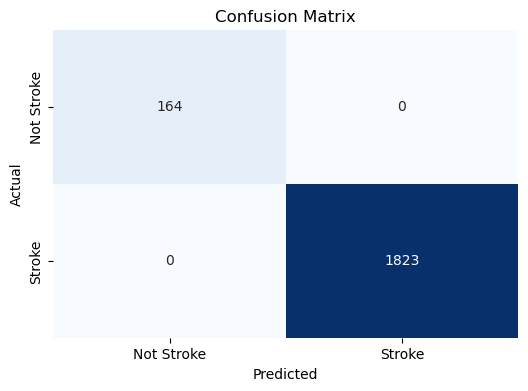


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       1.00      1.00      1.00       164
      Stroke       1.00      1.00      1.00      1823

    accuracy                           1.00      1987
   macro avg       1.00      1.00      1.00      1987
weighted avg       1.00      1.00      1.00      1987

ROC-AUC: 1.0


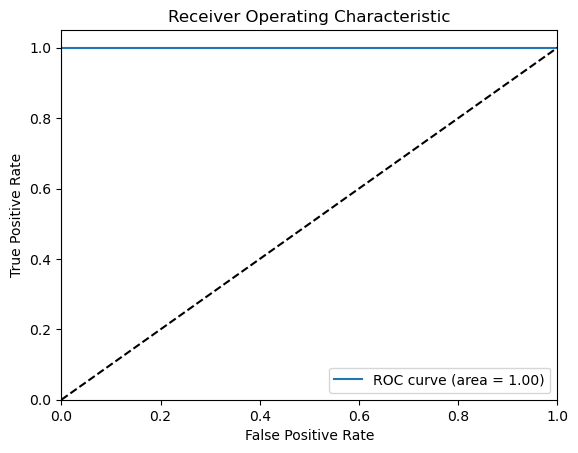

PR AUC: 1.0


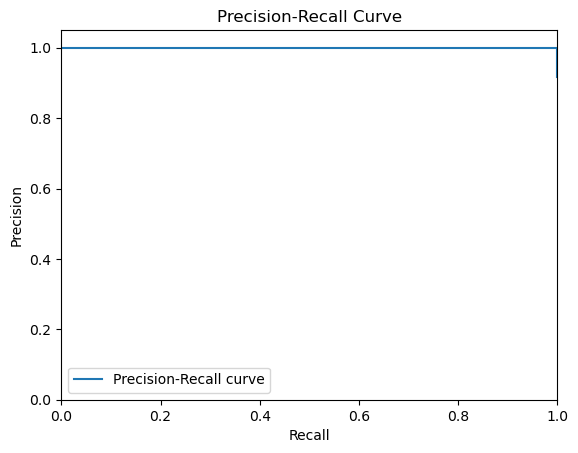

 77%|███████▋  | 10/13 [00:16<00:03,  1.27s/it]e:\anaconda\Lib\site-packages\xgboost\training.py:200: UserWarning: [18:28:46] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[ 164    0]
 [   0 1823]]


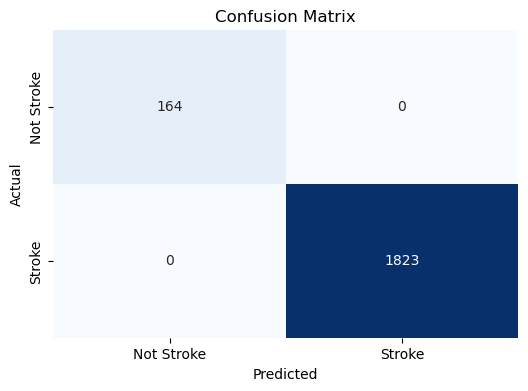


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       1.00      1.00      1.00       164
      Stroke       1.00      1.00      1.00      1823

    accuracy                           1.00      1987
   macro avg       1.00      1.00      1.00      1987
weighted avg       1.00      1.00      1.00      1987

ROC-AUC: 1.0


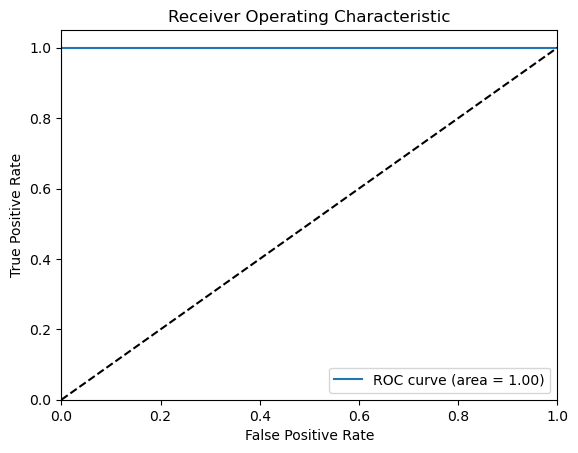

PR AUC: 1.0


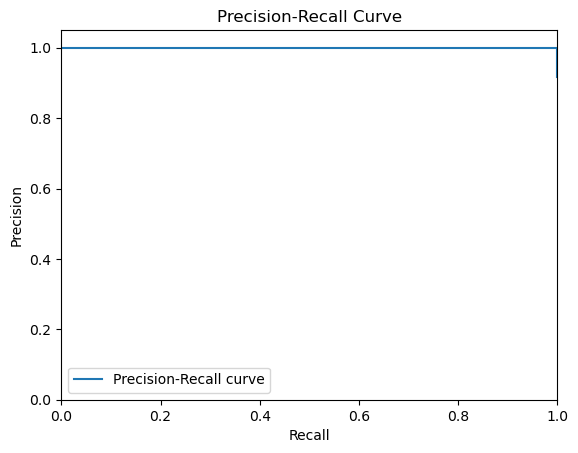

 85%|████████▍ | 11/13 [00:18<00:03,  1.64s/it]


Confusion Matrix:
 [[ 164    0]
 [   0 1823]]


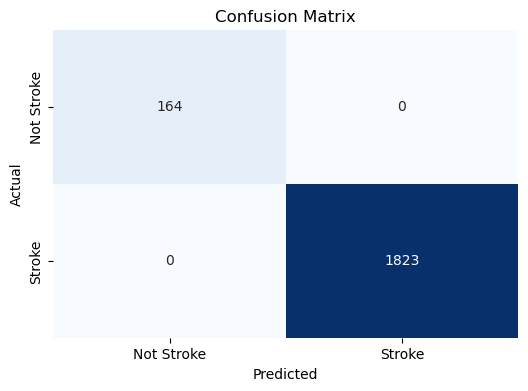


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       1.00      1.00      1.00       164
      Stroke       1.00      1.00      1.00      1823

    accuracy                           1.00      1987
   macro avg       1.00      1.00      1.00      1987
weighted avg       1.00      1.00      1.00      1987

ROC-AUC: 1.0


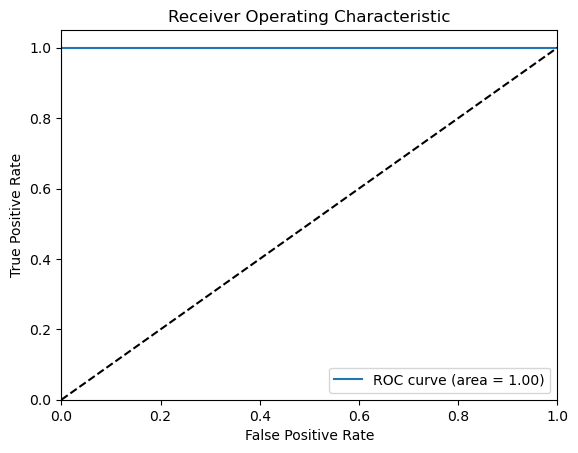

PR AUC: 1.0


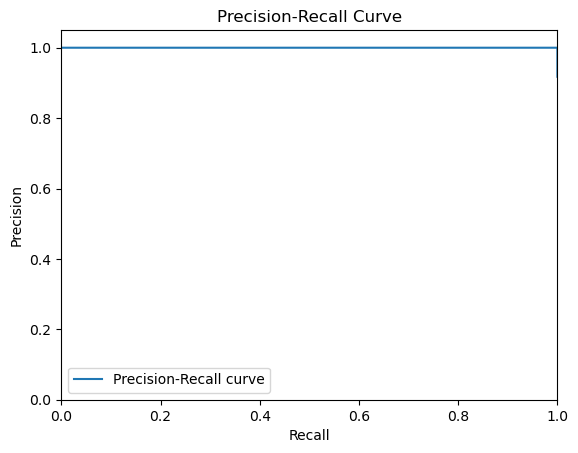

 92%|█████████▏| 12/13 [00:27<00:03,  3.75s/it]

[LightGBM] [Info] Number of positive: 7260, number of negative: 685
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001004 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 751
[LightGBM] [Info] Number of data points in the train set: 7945, number of used features: 8
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.913782 -> initscore=2.360716
[LightGBM] [Info] Start training from score 2.360716
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best 

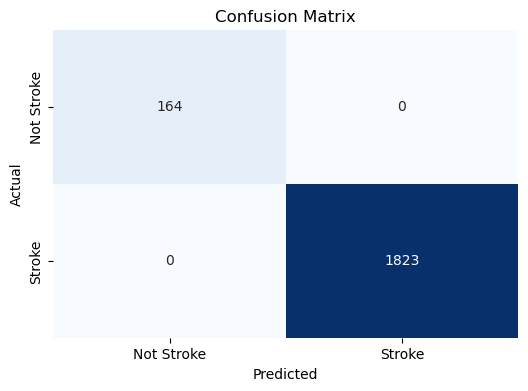


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       1.00      1.00      1.00       164
      Stroke       1.00      1.00      1.00      1823

    accuracy                           1.00      1987
   macro avg       1.00      1.00      1.00      1987
weighted avg       1.00      1.00      1.00      1987

ROC-AUC: 1.0


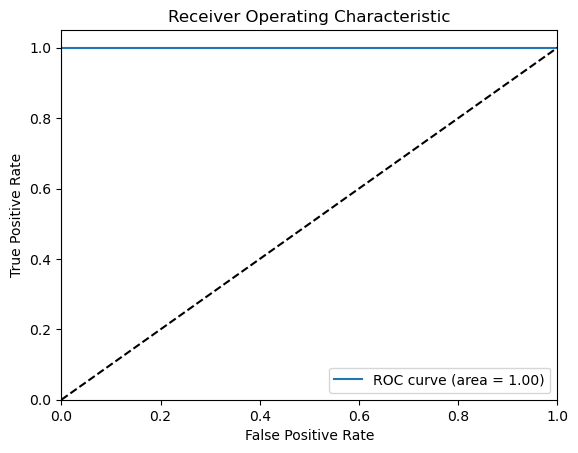

PR AUC: 1.0


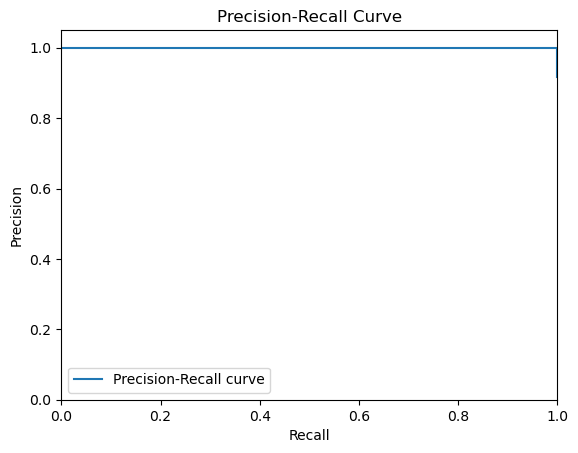

100%|██████████| 13/13 [00:28<00:00,  2.19s/it]


In [101]:
results = {}

for name, model in tqdm(models.items()):
    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred  = model.predict(X_test)
    
    

    cm = confusion_matrix(y_test, test_pred)
    print("\nConfusion Matrix:\n", cm)

    plt.figure(figsize=(6,4))
    sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
                xticklabels=['Not Stroke','Stroke']
                ,yticklabels=['Not Stroke','Stroke'])
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.title('Confusion Matrix')
    plt.show()

    # Full classification report
    print("\nClassification Report:\n")
    print(classification_report(y_test, test_pred,target_names=['Not Stroke','Stroke'],zero_division=0))

    y_pred_prob = model.predict_proba(X_test)[:, 1]
    roc_auc = roc_auc_score(y_test, y_pred_prob)
    print("ROC-AUC:", roc_auc)

    # ROC curve
    fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
    plt.plot([0, 1], [0, 1], 'k--') 
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic')
    plt.legend(loc="lower right")
    plt.show()

    pr_auc = average_precision_score(y_test, y_pred_prob)
    print("PR AUC:", pr_auc)

    precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve')
    plt.legend(loc="lower left")
    plt.show()

    results[name] = {
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Train Precision": precision_score(y_train, train_pred),
        "Test Precision": precision_score(y_test, test_pred),
        "Train Recall": recall_score(y_train, train_pred),
        "Test Recall": recall_score(y_test, test_pred),
        "Train F1 Score": f1_score(y_train, train_pred),
        "Test F1 Score": f1_score(y_test, test_pred),
        "Train Balanced Accuracy": balanced_accuracy_score(y_train, train_pred),
        "Test Balanced Accuracy": balanced_accuracy_score(y_test, test_pred),
        "ROC-AUC": roc_auc,
        "PR AUC": pr_auc

    }
    

In [102]:
res = pd.DataFrame(results)
res

,Logistic Regression,KNN,SVC,Decision Tree,Naive Bayes,Random Forest,Extra Trees,AdaBoost,Gradient Boosting,Hist Gradient Boosting,XGBoost,CatBoost,LightGBM
Train Accuracy,0.973820,0.932662,0.913782,1.0,0.990686,1.0,1.000000,1.0,1.0,1.0,1.0,1.0,1.0
Test Accuracy,0.964771,0.910418,0.917464,1.0,0.989935,1.0,0.988425,1.0,1.0,1.0,1.0,1.0,1.0
Train Precision,0.983676,0.941099,0.913782,1.0,0.990044,1.0,1.000000,1.0,1.0,1.0,1.0,1.0,1.0
Test Precision,0.983453,0.928609,0.917464,1.0,0.989680,1.0,0.988599,1.0,1.0,1.0,1.0,1.0,1.0
Train Recall,0.987741,0.988154,1.000000,1.0,0.999862,1.0,1.000000,1.0,1.0,1.0,1.0,1.0,1.0
Test Recall,0.978058,0.977510,1.000000,1.0,0.999451,1.0,0.998903,1.0,1.0,1.0,1.0,1.0,1.0
Train F1 Score,0.985704,0.964053,0.954949,1.0,0.994929,1.0,1.000000,1.0,1.0,1.0,1.0,1.0,1.0
Test F1 Score,0.980748,0.952432,0.956955,1.0,0.994541,1.0,0.993724,1.0,1.0,1.0,1.0,1.0,1.0
Train Balanced Accuracy,0.907009,0.666340,0.500000,1.0,0.946646,1.0,1.000000,1.0,1.0,1.0,1.0,1.0,1.0
Test Balanced Accuracy,0.897566,0.571072,0.500000,1.0,0.941799,1.0,0.935427,1.0,1.0,1.0,1.0,1.0,1.0
